In [1]:
import os
from kaggle_secrets import UserSecretsClient

secrets = UserSecretsClient()
def secret(name):
    try:
        return secrets.get_secret(name)
    except Exception:
        return None

for name in ["WANDB_API_KEY", "HF_TOKEN"]:
    if value := secret(name):
        os.environ[name] = value
if "WANDB_API_KEY" not in os.environ:  # run pushed via the Kaggle CLI has no Secrets: log offline, `wandb sync` later
    os.environ["WANDB_MODE"] = "offline"

REPO_DIR = "/kaggle/working/ai500-labs"
BRANCH = "main"
token = secret("GITHUB_TOKEN")
url = f"https://{token}@github.com/PavloKhomenko/ai500-labs.git" if token else "https://github.com/PavloKhomenko/ai500-labs.git"

In [2]:
# the token is passed only on the command line, origin keeps the public url (/kaggle/working gets saved)
if os.path.exists(REPO_DIR):
    !git -C {REPO_DIR} pull -q {url} {BRANCH}
else:
    !git clone -q -b {BRANCH} {url} {REPO_DIR}
    !git -C {REPO_DIR} remote set-url origin https://github.com/PavloKhomenko/ai500-labs.git
!git -C {REPO_DIR} log --oneline -1

da6c77f (HEAD -> main, origin/main, origin/HEAD) part 2 report done


In [3]:
# versions from lab-1/uv.lock; torch stays Kaggle's CUDA build
!pip install -q "transformers==5.18.0" "datasets==5.1.0" "accelerate==1.15.0" "peft==0.21.2" \
    "huggingface-hub==1.33.0" "wandb==0.30.0" "tabulate==0.10.0" "pyyaml==6.0.3"
# Kaggle ships torchao 0.10; peft 0.21 needs torchao > 0.16 and errors while dispatching LoRA layers, and we don't use it
!pip uninstall -q -y torchao

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 87.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.1/26.1 MB 72.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 38.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not c

In [4]:
import sys
sys.path.insert(0, f"{REPO_DIR}/lab-1/src")

import pandas as pd
import torch
import transformers
from transformers import AutoTokenizer

from lab1.common import load_config, out_dir
from lab1.data import prepare_part1_data
from lab1.part2 import wandb_log as wl
from lab1.part2.pretrain import load_model
from lab1.part1.evaluate import LongContextEvaluator, ResultsReport
from lab1.part1.finetune import LongLoRATrainer
%matplotlib inline

cfg = load_config()
p1 = cfg["part1"]
device = torch.device("cuda")
env = {"torch": torch.__version__, "transformers": transformers.__version__, "gpu": torch.cuda.get_device_name()}
print(env)

def start_run(name, job_type, **extra):
    return wl.init_run(cfg, name, job_type, config={**p1, **env, **extra}, group="part1",
                       project=cfg["wandb"]["part1_project"])

{'torch': '2.11.0+cu128', 'transformers': '5.18.0', 'gpu': 'Tesla T4'}


In [5]:
import glob
import shutil
from pathlib import Path

# input: dataset khomenkopavlo/lab1-part1-outputs (flat files from the lab1-part1 output)
found = glob.glob("/kaggle/input/**/data.pt", recursive=True)
assert found, "add the lab1-part1-outputs dataset as an Input"
prev = Path(found[0]).parent
for f in prev.iterdir():
    sub = "data" if f.name in ("data.pt", "eval_doc_keys.json") else "kv_cache" if f.stem == "kv_cache" else "eval"
    shutil.copy(f, out_dir(cfg, "part1", sub) / f.name)
print("restored from", prev)

tok = AutoTokenizer.from_pretrained(p1["model"])
data = prepare_part1_data(cfg, tok, out_dir(cfg, "part1", "data"))
eval_dir, fig_dir = out_dir(cfg, "part1", "eval"), out_dir(cfg, "part1", "figures")
print({k: tuple(v.shape) for k, v in data.items() if torch.is_tensor(v)})
print(sorted(f.name for f in eval_dir.glob("*.json")))

restored from /kaggle/input/lab1-part1-outputs


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/47.0k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 15.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

tokenizer.model: reconstructing file:   0%|          |  0.00B / 2.41MB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

{'uk': (100, 16385), 'en': (94, 16385), 'train': (800, 8192), 'uk_bytes': (100, 3), 'en_bytes': (94, 3)}
['loss_dynamic_ntk.json', 'loss_linear.json', 'loss_none.json', 'loss_ntk.json', 'loss_yarn.json', 'passkey_dynamic_ntk.json', 'passkey_linear.json', 'passkey_none.json', 'passkey_ntk.json', 'passkey_yarn.json']


In [6]:
ft_dir = out_dir(cfg, "part1", "finetune")

start_run(f"finetune-{p1['finetune']['method']}", "train", **p1["finetune"])
trainer = LongLoRATrainer(load_model(p1["model"], device), p1, seed=cfg["seed"])
trainer.train(data["train"], ft_dir / "train_log.jsonl", max_steps=None)  # max_steps=5 for timing
trainer.save(ft_dir / "trainable.pt")
wl.finish()

wandb: Tracking run with wandb version 0.30.0
wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /kaggle/working/wandb/offline-run-20261013_183035-bd2tdj77
wandb: View this run in the terminal with `wandb leet`


model.safetensors.index.json:   0%|          | 0.00/459k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

rope=yarn s=4 seq_len=None: inv_freq[:3]=[1.0, 0.8146172165870667, 0.663601279258728] inv_freq[-3:]=[9.249307595382561e-07, 7.5346451922087e-07, 6.137851755738666e-07] attention_scaling=1.1386
trainable: LoRA 1.28M, embeddings + norms 131.12M
{"step": 0, "loss": 1.8904923498630524, "grad_norm": 1.6274203062057495, "lr": 1e-05, "sec_per_step": 21.19844961166382, "max_mem_gb": 8.460440635681152}
{"step": 10, "loss": 2.077825427055359, "grad_norm": 2.0302000045776367, "lr": 0.00011000000000000002, "sec_per_step": 21.8565890789032, "max_mem_gb": 9.446898460388184}
{"step": 20, "loss": 1.8276942372322083, "grad_norm": 1.638645052909851, "lr": 0.0002, "sec_per_step": 21.729528188705444, "max_mem_gb": 9.446898460388184}
{"step": 30, "loss": 2.0137051343917847, "grad_norm": 1.6589148044586182, "lr": 0.00019863269777109873, "sec_per_step": 21.852269172668457, "max_mem_gb": 9.446898460388184}
{"step": 40, "loss": 2.0783177316188812, "grad_norm": 1.6326030492782593, "lr": 0.00019457233587073176, 

wandb: 
wandb: Run history:
wandb:    train/grad_norm █▃▆▃▄▄▃▄▃▃▅▄▃▅▂▂▂▃▃▄▃▂▂▃▂▃▄▂▁▂▁▂▄▂▂▂▂▃▁▂
wandb:         train/loss ▄▆▄▅▄▂▄▁▄█▄▅▃▃▄▆▄▆▃▃▄▅▃▅▄▁▂▃▂▃▅▂▃▃▅▂▂▄▄▆
wandb:           train/lr ▂▅▅▆▇██████████▇▇▇▇▆▆▆▆▆▅▅▅▅▅▄▃▃▂▂▂▁▁▁▁▁
wandb:   train/max_mem_gb ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: train/sec_per_step ▃▄▄▃▂▁▃▄▂▂▃▂▃▂▃▄▃▃▂▃▄█▂▂▃▃▄▃▃▄▃▂▃▄▄▃▂▃▂▃
wandb: 
wandb: Run summary:
wandb:    train/grad_norm 1.55908
wandb:         train/loss 1.99272
wandb:           train/lr 2e-05
wandb:   train/max_mem_gb 9.4469
wandb: train/sec_per_step 21.83178
wandb: 
wandb: You can sync this run to the cloud by running:
wandb: wandb sync /kaggle/working/wandb/offline-run-20261013_183035-bd2tdj77
wandb: Find logs at: ./wandb/offline-run-20261013_183035-bd2tdj77/logs


In [7]:
del trainer
torch.cuda.empty_cache()
method = p1["finetune"]["method"]
model = LongLoRATrainer.load_finetuned(load_model(p1["model"], device), ft_dir / "trainable.pt", p1)
evaluator = LongContextEvaluator(model, tok, p1, seed=cfg["seed"])

start_run(f"eval-{method}-ft", "eval", method=method, finetuned=True)
evaluator.evaluate(method, data, eval_dir, tag=f"{method}-ft")
wl.finish()

Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

rope=yarn s=4 seq_len=None: inv_freq[:3]=[1.0, 0.8146172165870667, 0.663601279258728] inv_freq[-3:]=[9.249307595382561e-07, 7.5346451922087e-07, 6.137851755738666e-07] attention_scaling=1.1386


wandb: Tracking run with wandb version 0.30.0
wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /kaggle/working/wandb/offline-run-20261013_194406-5bhpsmjr
wandb: View this run in the terminal with `wandb leet`


rope=yarn s=4 seq_len=None: inv_freq[:3]=[1.0, 0.814453125, 0.66357421875] inv_freq[-3:]=[9.5367431640625e-07, 7.748603820800781e-07, 5.960464477539062e-07] attention_scaling=1.1386
[yarn uk] first document 3.0s -> ~5.1 min for 100
rope=yarn s=4 seq_len=None: inv_freq[:3]=[1.0, 0.814453125, 0.66357421875] inv_freq[-3:]=[9.5367431640625e-07, 7.748603820800781e-07, 5.960464477539062e-07] attention_scaling=1.1386
[yarn en] first document 3.1s -> ~4.9 min for 94
rope=yarn s=4 seq_len=None: inv_freq[:3]=[1.0, 0.814453125, 0.66357421875] inv_freq[-3:]=[9.5367431640625e-07, 7.748603820800781e-07, 5.960464477539062e-07] attention_scaling=1.1386


[transformers] This is a friendly reminder - the current text generation call has exceeded the model's predefined maximum length (4096). Depending on the model, you may observe exceptions, performance degradation, or nothing at all.


passkey yarn uk L=4096 depth=0.1: 20/20
passkey yarn uk L=4096 depth=0.5: 20/20
passkey yarn uk L=4096 depth=0.9: 20/20
passkey yarn uk L=8192 depth=0.1: 20/20
passkey yarn uk L=8192 depth=0.5: 20/20
passkey yarn uk L=8192 depth=0.9: 20/20
passkey yarn uk L=16384 depth=0.1: 20/20
passkey yarn uk L=16384 depth=0.5: 20/20
passkey yarn uk L=16384 depth=0.9: 20/20
passkey yarn en L=4096 depth=0.1: 20/20
passkey yarn en L=4096 depth=0.5: 20/20
passkey yarn en L=4096 depth=0.9: 20/20
passkey yarn en L=8192 depth=0.1: 20/20
passkey yarn en L=8192 depth=0.5: 20/20
passkey yarn en L=8192 depth=0.9: 20/20
passkey yarn en L=16384 depth=0.1: 20/20
passkey yarn en L=16384 depth=0.5: 20/20


wandb: 
wandb: Run history:
wandb:  loss/en ▁▅▇▆▆▇▇▇▆▆▆▆▅▅▆█
wandb:  loss/uk █▃▄▄▃▃▃▂▂▁▂▃▄▃▂▁
wandb: position ▁▁▂▂▃▃▄▄▅▅▆▆▇▇██▁▁▂▂▃▃▄▄▅▅▆▆▇▇██
wandb: 
wandb: Run summary:
wandb:    bpb/en_16384 0.99535
wandb:     bpb/en_4096 0.99498
wandb:     bpb/en_8192 0.99494
wandb:    bpb/uk_16384 0.46095
wandb:     bpb/uk_4096 0.4677
wandb:     bpb/uk_8192 0.46016
wandb:         loss/en 2.6584
wandb:         loss/uk 1.72662
wandb: minutes/loss_en 4.92068
wandb: minutes/loss_uk 5.27152
wandb:             +20 ...
wandb: 
wandb: You can sync this run to the cloud by running:
wandb: wandb sync /kaggle/working/wandb/offline-run-20261013_194406-5bhpsmjr
wandb: Find logs at: ./wandb/offline-run-20261013_194406-5bhpsmjr/logs


passkey yarn en L=16384 depth=0.9: 20/20


wandb: Tracking run with wandb version 0.30.0
wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /kaggle/working/wandb/offline-run-20261013_200431-am1jmcey
wandb: View this run in the terminal with `wandb leet`
wandb: You can sync this run to the cloud by running:
wandb: wandb sync /kaggle/working/wandb/offline-run-20261013_200431-am1jmcey
wandb: Find logs at: ./wandb/offline-run-20261013_200431-am1jmcey/logs


,method,lang,bpb@4096,bpb@8192,bpb@16384
0,dynamic_ntk,uk,0.466998,0.466137,0.505754
1,dynamic_ntk,en,0.874308,0.893632,0.966207
2,linear,uk,1.260923,1.262737,1.280714
3,linear,en,1.882796,1.887270,1.905248
4,none,uk,0.467028,0.988911,1.460010
5,none,en,0.874330,1.638758,2.211013
6,ntk,uk,0.470913,0.469653,0.925111
7,ntk,en,0.888932,0.891104,1.519516
8,yarn-ft,uk,0.467701,0.460164,0.460953
9,yarn-ft,en,0.994979,0.994941,0.995352


,method,lang,4096@0.1,4096@0.5,4096@0.9,8192@0.1,8192@0.5,8192@0.9,16384@0.1,16384@0.5,16384@0.9
0,dynamic_ntk,en,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,0.90
1,dynamic_ntk,uk,1.0,1.0,1.0,0.95,1.0,1.0,1.0,1.0,0.95
2,linear,en,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.00
3,linear,uk,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.00
4,none,en,1.0,1.0,1.0,0.00,0.0,0.0,0.0,0.0,0.00
5,none,uk,1.0,1.0,1.0,0.00,0.0,0.0,0.0,0.0,0.00
6,ntk,en,1.0,1.0,1.0,1.00,1.0,1.0,0.0,0.0,0.00
7,ntk,uk,1.0,1.0,1.0,1.00,1.0,1.0,0.0,0.0,0.00
8,yarn,en,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.00
9,yarn,uk,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.00


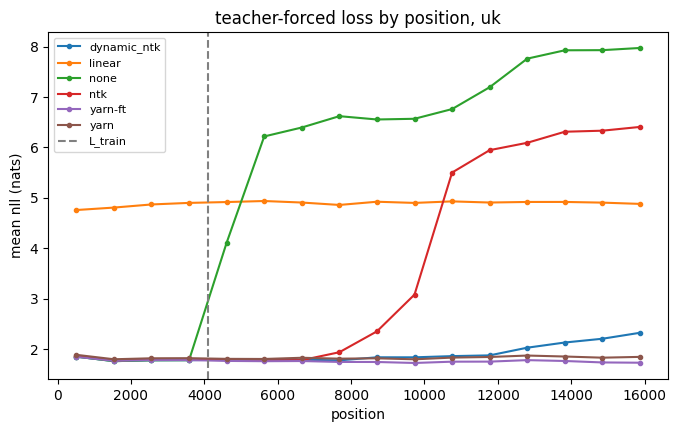

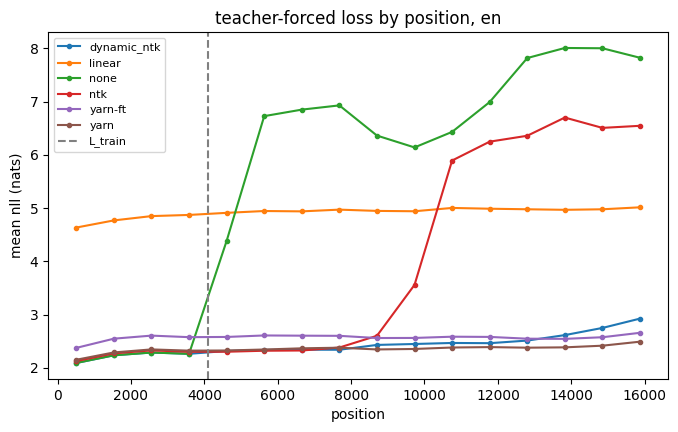

In [8]:
report = ResultsReport(eval_dir, fig_dir, p1["l_train"], p1["bin_size"])
start_run("eval-summary", "analysis")
report.loss_plot("uk")
report.loss_plot("en")
bpb, passkey = report.bpb_table(), report.passkey_table()
wl.finish()
display(bpb, passkey)